## Упражнения

In [1]:
import warnings
warnings.filterwarnings('ignore')
from io import BytesIO
import requests
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.integrate import quad
from statsmodels.tsa.arima_process import ArmaProcess
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose
np.random.seed(0) # Reproducibility

In [3]:
# метод вывода графиков
def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1,1, figsize=(10, 3.5))
    ax.plot(x, y, 'k-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax

### Упражнение 1

- Загрузите два временных ряда `stationarity_ts1` и `stationarity_ts2`, выполнив код ниже.

In [4]:
# зугрузка 1-го датасета
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts1.npy?download=1")
response.raise_for_status()
stationarity_ts1 = np.load(BytesIO(response.content))
print(len(stationarity_ts1))

# зугрузка 2-го датасета
response = requests.get("https://zenodo.org/records/10897398/files/stationarity_ts2.npy?download=1")
response.raise_for_status()
stationarity_ts2 = np.load(BytesIO(response.content))
print(len(stationarity_ts2))

100
100


1. Постройте два временных ряда с помощью графика последовательности запусков.
4. На основе графика обсудите, является ли каждый временной ряд стационарным или нет.

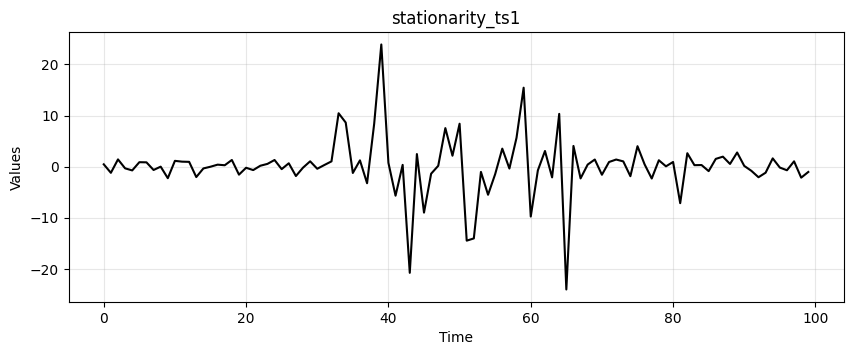

In [5]:
run_sequence_plot(np.arange(len(stationarity_ts1)), stationarity_ts1, title="stationarity_ts1");

In [8]:
# проверка стационарности: ADF-тест
adf_result = adfuller(stationarity_ts1)
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: -3.0324
p-value:       0.0320
Критические значения:
   1%: -3.5043
   5%: -2.8939
   10%: -2.5840

→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)


На глаз stationarity_ts1 не является стационарным рядом, т.к. наблюдается изменение дисперсии. Но ADF-тест и p-value указывают на стационарность.

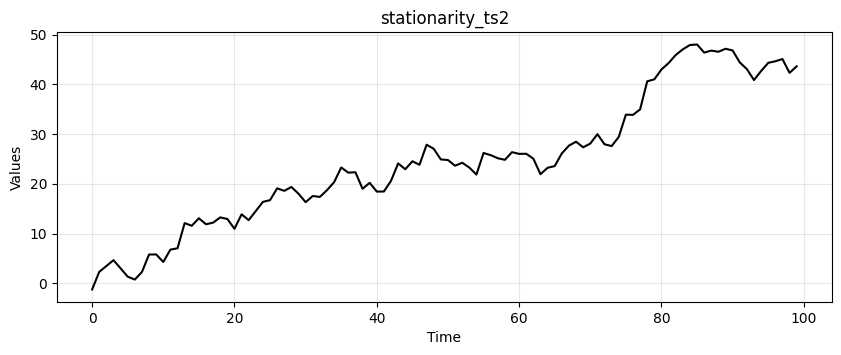

In [9]:
run_sequence_plot(np.arange(len(stationarity_ts2)), stationarity_ts2, title="stationarity_ts2");

In [10]:
# проверка стационарности: ADF-тест
adf_result = adfuller(stationarity_ts2)
print("Результаты ADF-теста на стационарность")
print(f"ADF-статистика: {adf_result[0]:.4f}")
print(f"p-value:       {adf_result[1]:.4f}")
print(f"Критические значения:")
for key, value in adf_result[4].items():
  print(f"   {key}: {value:.4f}")

# интерпретация
if adf_result[1] <= 0.05:
  print("\n→ Ряд СТАЦИОНАРЕН (нулевая гипотеза отвергнута)")
else:
  print("\n→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)")

Результаты ADF-теста на стационарность
ADF-статистика: -1.3223
p-value:       0.6189
Критические значения:
   1%: -3.4982
   5%: -2.8912
   10%: -2.5826

→ Ряд НЕСТАЦИОНАРЕН (нулевая гипотеза принимается)


На глаз stationarity_ts2 не является стационарным рядом, т.к. наблюдается изменение среднего. ADF-тест подтверждает это предположение, а p-value - нет.

### Упражнение 2

Используйте следующие инструменты, чтобы определить, являются ли временные ряды `stationarity_ts1` и `stationarity_ts2` стационарными или нет.

1. Сводная статистика по фрагментам.
2. Гистограммы.
3. Расширенный тест Дики-Фуллера.

Обсудите результат, полученный с помощью каждого метода.

Сводная статистика для stationarity_ts1
Chunk    Mean       Std       
------------------------------
Chunk 1  0.039      1.032     
Chunk 2  1.008      7.732     
Chunk 3  -0.930     8.158     
Chunk 4  0.055      2.172     

Сводная статистика для stationarity_ts2
Chunk    Mean       Std       
------------------------------
Chunk 1  8.070      5.195     
Chunk 2  20.871     3.231     
Chunk 3  25.782     2.198     
Chunk 4  43.398     4.072     


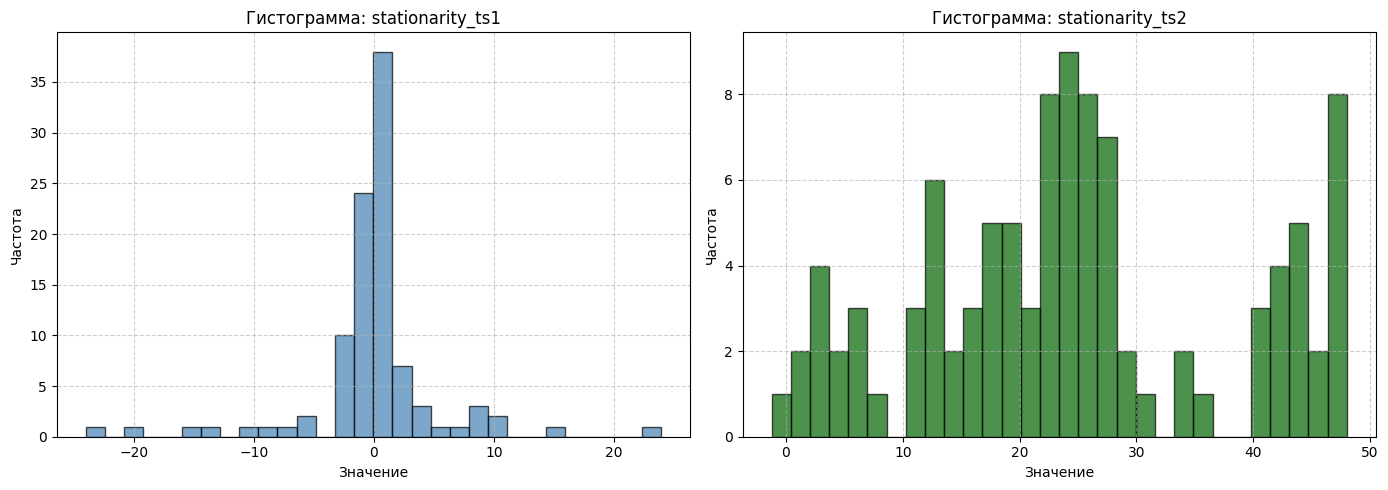

Ряд 1 — p-value: 0.0320 → нестационарен
Ряд 2 — p-value: 0.6189 → нестационарен
Основные статистики:
stationarity_ts1 — Среднее: 0.043, Std: 5.673
stationarity_ts2 — Среднее: 24.530, Std: 13.213


In [12]:
def chunk_statistics(ts, n_chunks=4):
  """
  Разбивает временной ряд на n_chunks частей и вычисляет среднее и std для каждой.
  """
  chunk_size = len(ts) // n_chunks
  print(f"{'Chunk':<8} {'Mean':<10} {'Std':<10}")
  print("-" * 30)

  for i in range(n_chunks):
    start = i * chunk_size
    end = (i + 1) * chunk_size if i < n_chunks - 1 else len(ts)  # последний фрагмент берет остаток
    chunk = ts[start:end]
    mean_val = np.mean(chunk)
    std_val = np.std(chunk, ddof=1)  # ddof=1 для несмещённой оценки
    print(f"Chunk {i+1:<2} {mean_val:<10.3f} {std_val:<10.3f}")

print("Сводная статистика для stationarity_ts1")
chunk_statistics(stationarity_ts1)

print("\nСводная статистика для stationarity_ts2")
chunk_statistics(stationarity_ts2)

# построение гистограмм
plt.figure(figsize=(14, 5))

# гистограмма stationarity_ts1
plt.subplot(1, 2, 1)
plt.hist(stationarity_ts1, bins=30, color='steelblue', alpha=0.7, edgecolor='black')
plt.title('Гистограмма: stationarity_ts1')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.grid(True, linestyle='--', alpha=0.6)

# гистограмма stationarity_ts2
plt.subplot(1, 2, 2)
plt.hist(stationarity_ts2, bins=30, color='darkgreen', alpha=0.7, edgecolor='black')
plt.title('Гистограмма: stationarity_ts2')
plt.xlabel('Значение')
plt.ylabel('Частота')
plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

# ADF-тест для ряда stationarity_ts1
result1 = adfuller(stationarity_ts1)
print(f"Ряд 1 — p-value: {result1[1]:.4f} → {'стационарен' if result1[1] < 0.01 else 'нестационарен'}")

# ADF-тест для ряда stationarity_ts2
result2 = adfuller(stationarity_ts2)
print(f"Ряд 2 — p-value: {result2[1]:.4f} → {'стационарен' if result2[1] < 0.01 else 'нестационарен'}")

# дополнительно: вывод основных статистик
print("Основные статистики:")
print(f"stationarity_ts1 — Среднее: {np.mean(stationarity_ts1):.3f}, Std: {np.std(stationarity_ts1):.3f}")
print(f"stationarity_ts2 — Среднее: {np.mean(stationarity_ts2):.3f}, Std: {np.std(stationarity_ts2):.3f}")

Сводная статистика указывает на нестационарность обоих рядов (у первого меняется дисперсия, у второго меняется среднее). P-value у обоих рядов также указывает на нестационарность.

### Упражнение 3
Если один или оба набора данных из упражнений один и два нестационарны, примените преобразования, которые вы изучили в этом разделе, чтобы сделать их таковыми. Затем примените методы, которые вы изучили, чтобы обеспечить стационарность.

Ряд 1 — p-value: 0.0000 → стационарен
Ряд 2 — p-value: 0.0000 → стационарен


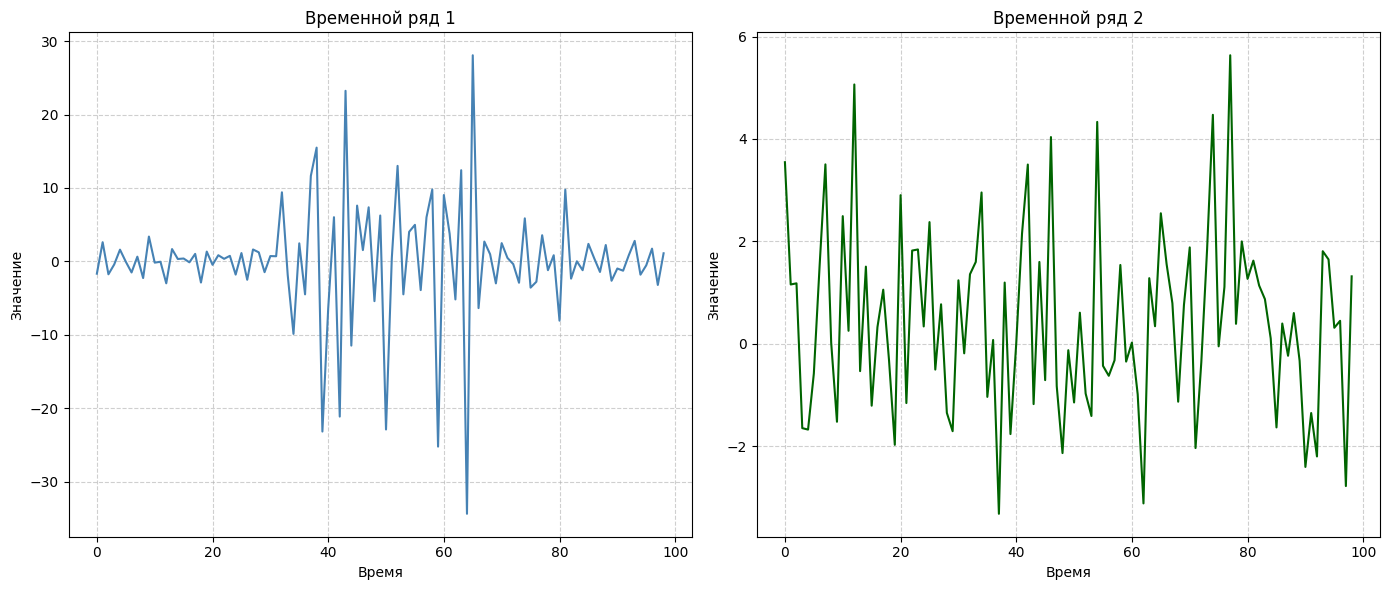

In [13]:
# дифференцирование
stationarity_ts1_diff = np.diff(stationarity_ts1)
stationarity_ts2_diff = np.diff(stationarity_ts2)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(stationarity_ts1_diff, color='steelblue')
plt.title('Временной ряд 1')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(True, linestyle='--', alpha=0.6)

plt.subplot(1, 2, 2)
plt.plot(stationarity_ts2_diff, color='darkgreen')
plt.title('Временной ряд 2')
plt.xlabel('Время')
plt.ylabel('Значение')
plt.grid(True, linestyle='--', alpha=0.6)

result1 = adfuller(stationarity_ts1_diff)
result2 = adfuller(stationarity_ts2_diff)
print(f"Ряд 1 — p-value: {result1[1]:.4f} → {'стационарен' if result1[1] < 0.01 else 'нестационарен'}")
print(f"Ряд 2 — p-value: {result2[1]:.4f} → {'стационарен' if result2[1] < 0.01 else 'нестационарен'}")

plt.tight_layout()
plt.show()

Ряд stationarity_ts1 после дифференцирования сохранил гетероскедастичность, однако стал стационарным. <p>Ряд stationarity_ts2 после дифференцирования утратил тренд, в нем можно заметить постоянное матожидание и дисперсию, поэтому он стал стационарным.